In [9]:
import scanpy as sc
import os
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import random
import pandas as pd
import gseapy as gp
SEED = 0
np.random.seed(SEED)
random.seed(SEED)


my_cmap = LinearSegmentedColormap.from_list(
    "soft_rdbl", ["#53b1dc", "#FFFFFF", "#EE6677"], N=256
)


from matplotlib import font_manager

font_dir = "/users/PAS2148/tiger/.local/share/fonts/arial"
for f in font_manager.findSystemFonts(fontpaths=[font_dir]):
    font_manager.fontManager.addfont(f)

plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.unicode_minus"] = False

figure_save_path = "Supplementary_Fig_7_figures"
os.makedirs(figure_save_path, exist_ok=True)




## Supplementary Fig. 7

In [10]:
enrichment_results = pd.read_excel("/fs/ess/PAS2148/huchen/scRNA_analysis_result/Mayo_WL_culture/Culture/final_Nov_3/Cultured_Pathway.xlsx", sheet_name=None)

Alveolar 1


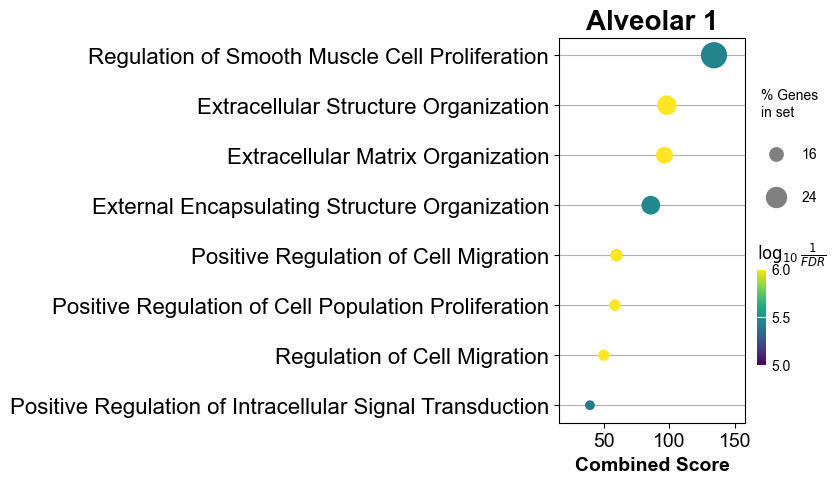

Alveolar 2


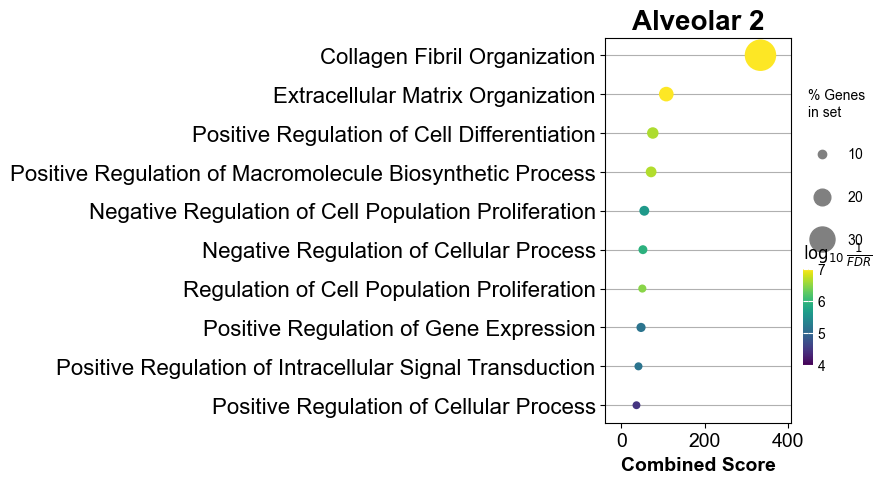

Adventitial


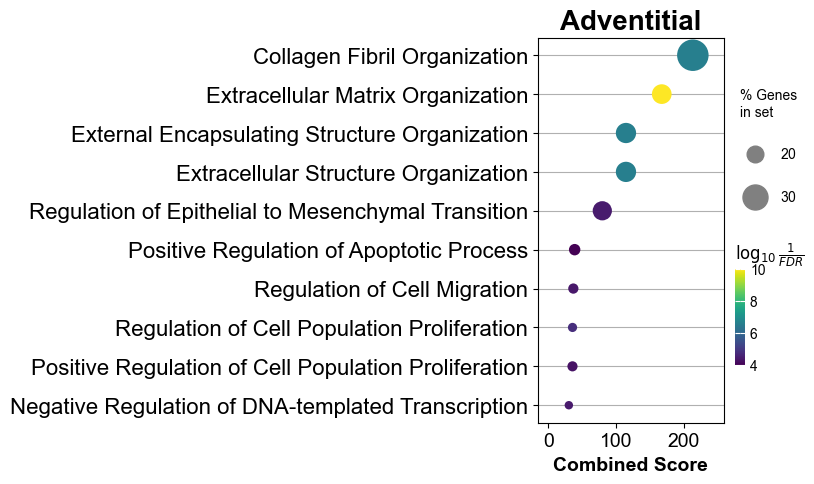

Inflammatory


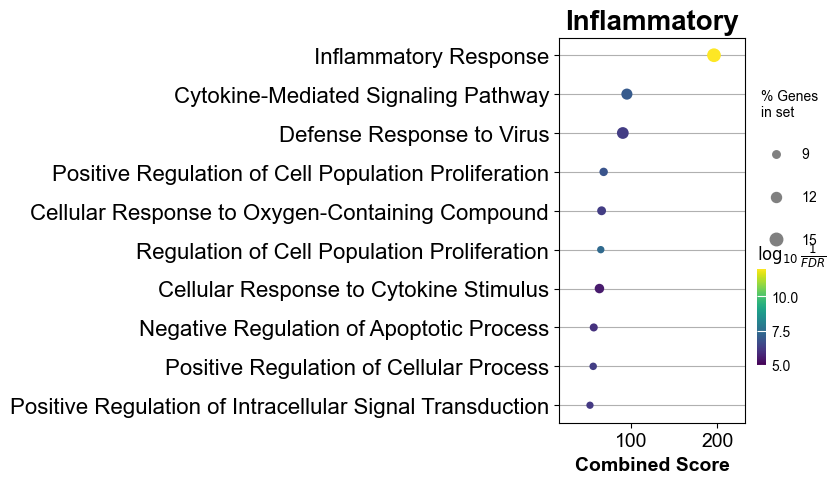

SMCs


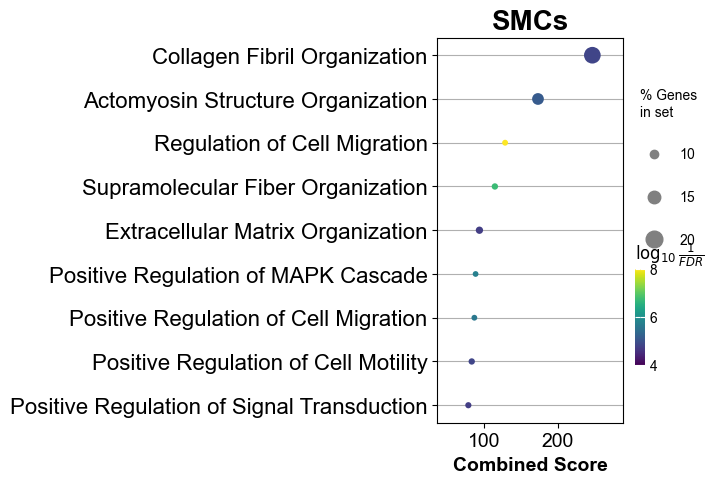

Senescence-like


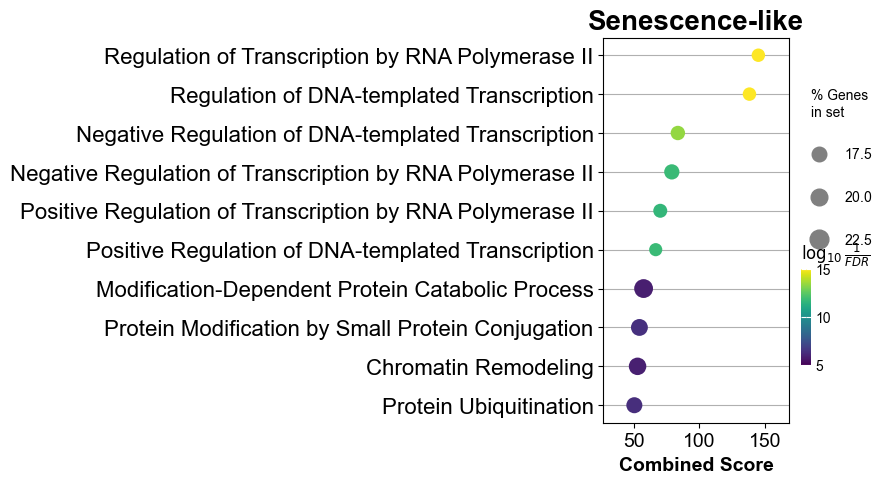

Proliferating


In [11]:
# dotplot
for cluster, df in enrichment_results.items():
    print(cluster)
    if cluster == "Proliferating":
        continue

    df = df.copy()
    df.Term = df.Term.str.split(r" \(GO").str[0]

    df_top = df.head(10).copy()

    if cluster == "Alveolar 1":
        df_top = df_top[~df_top.Term.isin(["Synapse Assembly", "Nervous System Development"])]
    elif cluster == "SMCs":
        df_top = df_top[df_top.Term != "Nervous System Development"]

    gp.dotplot(
        df_top,
        figsize=(3, 5),
        title=cluster,
        cmap="viridis",
        size=10
    )
    plt.savefig(
        f"{figure_save_path}/{cluster.replace(' ', '_')}_Pathway.pdf",
        bbox_inches="tight"
    )
    plt.show()


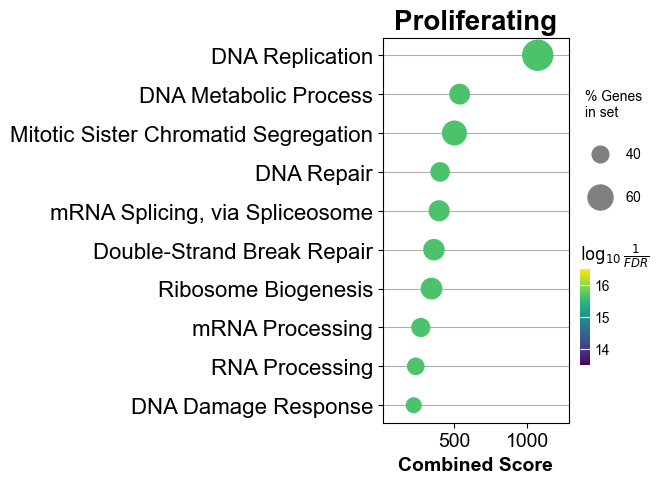

In [12]:
df = enrichment_results['Proliferating']
df.Term = df.Term.str.split(" \(GO").str[0]
gp.dotplot(df, figsize=(3,5), title=cluster, cmap = "viridis", size=5, top_term=10)
plt.savefig(f"{figure_save_path}/Proliferating_Pathway.pdf", bbox_inches='tight')
plt.show()